# Bonus B5: How to build an agent and a workflow with Microsoft Agent Framework

**Notebook 1 of 2: meet the framework on a leave request**

## Goal

Sara wants three days off. Somebody has to ask her manager, and only a yes may put the days in the team's calendar.
We build that as a **workflow** in Microsoft Agent Framework: a few steps, joined by edges that our code fixes. The
step that asks the manager waits for the answer, and the framework saves the waiting question in a file. Then we
answer that one saved question twice and count the entries in the calendar. In the last part an **agent** writes the
note to the manager as the first step of the workflow, and we check which part of the workflow still makes
sure a person signs before anything is booked.

Nothing here touches the music shop yet. This notebook is the playground; notebook 2 takes the same framework to
the Chinook support desk.

## What you will learn

- How to write a workflow step, join steps with an edge, run the workflow and read its events.
- How a step asks a person a question and waits, and how our code sends the answer back.
- How to save a waiting workflow in a checkpoint file, read that file, and continue from it with new objects.
- Why answering one checkpoint twice repeats the booking, and how to make the booking safe to repeat.
- How to build an `Agent` with a tool, and use it as one step of a workflow whose edges stay in our code.

## Setup

This lab has its own environment: select the kernel `bonus/B5_Microsoft_Agent_Framework/.venv` (the README says how
to create it). The first cell is the same in every lab: it finds the repository folder, reads the model name from
`models.env`, and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Parts A to D call no model at all. The model, and the key, are used only in Part E.

---

## Part A: Write one step and run it as a workflow

A leave request has to go through a few steps in a fixed order. In Microsoft Agent Framework a fixed order of steps
is a **workflow**, and we start with the smallest one there is: one step.

### The request and the calendar

The request is a small dictionary. The team's calendar is a Python list, so that we can print it after every run and
see exactly what was booked.

In [2]:
request = {"id": "leave-1", "name": "Sara", "days": 3, "start": "14 December"}

# The team's calendar: every booking is appended here
BOOKED = []

print(request)

{'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}


Four fields: `id` names this request, `name` is who asks, `days` is how many days, `start` is the first day off.

### A step is a function with a context

The framework's word for a step is an **executor**. The simplest executor is a function with `@executor` above it.
It gets two things:

- the **message** that arrived at this step (here the request dictionary);
- a **context**, `ctx`, which is how the step passes something on.

Our first step books the days. `ctx.yield_output(...)` hands a result to whoever ran the workflow.

Two details in the first line of the function:

- `async def`, and `await` in the last line: the framework's steps are `async` functions, and `await` runs an
  `async` call and waits for it. In a notebook we can also write `await` directly in a cell.
- `WorkflowContext[Never, str]` says what this step may pass on. The first type is what it may send to a next step:
  `Never`, because it sends nothing on. The second is what it may give as a result of the workflow: a string.

The `print` in the first line is how we will know, for the rest of this notebook, that the step really ran.

In [3]:
from typing import Never
from agent_framework import WorkflowBuilder, WorkflowContext, executor


@executor(id="book_days")
async def book_days(request: dict, ctx: WorkflowContext[Never, str]):
    print("STEP RAN: book_days")
    BOOKED.append(request)
    await ctx.yield_output(f"Booked {request['days']} days for {request['name']}.")

### Build the workflow and run it

`WorkflowBuilder` collects the steps. `start_executor` is the step that receives the workflow's input, and
`build()` returns the `Workflow` object. Then `workflow.run(request)` sends our dictionary to the start step.

A run returns a list of **events**: a record of what happened, in order. We print each event's type, the step it
belongs to, and its data.

In [4]:
workflow = WorkflowBuilder(name="leave", start_executor=book_days).build()

run = await workflow.run(request)

for event in run:
    print(f"{event.type:20} | {str(event.executor_id):10} | {event.data}")

STEP RAN: book_days
superstep_started    | None       | None
executor_invoked     | book_days  | {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}
output               | book_days  | Booked 3 days for Sara.
executor_completed   | book_days  | ['Booked 3 days for Sara.']
superstep_completed  | None       | None


First the `STEP RAN` line, then five events. Read them top to bottom:

| Event | What it records |
|---|---|
| `superstep_started` | a round of work began. In one **superstep** every step that has a message waiting runs once |
| `executor_invoked` | `book_days` received the request (its data is the message that arrived) |
| `output` | `book_days` called `yield_output`, with the sentence it wrote |
| `executor_completed` | `book_days` finished |
| `superstep_completed` | the round ended. No step has a message waiting, so the run is over |

Two shortcuts read the same run without the loop: `get_outputs()` collects the `output` events, and our own list
shows what was booked.

In [5]:
print("outputs:", run.get_outputs())
print("booked: ", BOOKED)

outputs: ['Booked 3 days for Sara.']
booked:  [{'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}]


One output and one entry in the calendar: Sara's three days are booked.

**Notice** what is missing: nobody asked her manager. A workflow with one step does that step, at once. To put a
person between the request and the booking we need a second step, and that step has to be able to wait.

**Checkpoint A.** One `STEP RAN: book_days` line, five events with `book_days` in three of them, the output
`Booked 3 days for Sara.` and one entry in `BOOKED`.

---

## Part B: Add a step that asks a person and waits

The manager may answer in a minute or next Monday. A step cannot sit inside an `input()` call for a week, so the
framework splits asking in two:

1. **Ask.** The step calls `ctx.request_info(...)` with the question, and ends. The workflow stops there, with the
   question waiting.
2. **Receive the answer.** When our code sends an answer in, the framework calls a second method of the same step
   and gives it both the original question and the answer.

A step with two methods is written as a class. `@handler` marks the method that receives the message, and
`@response_handler` marks the method that receives the answer:

- `ask` passes the request to `request_info` as the question's data. `response_type=bool` says the answer must be
  `True` or `False`.
- `answer` gets the same request back, plus `approved`. On a yes it calls `ctx.send_message(request)`, which sends
  the request along the edge to the next step. On a no it ends the workflow with an output, and nothing is sent on.
- `ask` declares `WorkflowContext[dict]`, with one type: a `dict` may be sent on, and there is no output of the workflow. `answer` declares `WorkflowContext[dict, str]`, because on a no it gives a string as output. `ask` and `answer` are two methods of one step, `ask_manager`, and `ask` itself sends nothing. The framework checks the edge against the types of both methods together, and the `dict` that travels along it is the one `answer` sends.

In [6]:
from agent_framework import Executor, handler, response_handler


class AskManager(Executor):
    @handler
    async def ask(self, request: dict, ctx: WorkflowContext[dict]):
        print("STEP RAN: ask_manager asks")
        await ctx.request_info(request_data=request, response_type=bool)

    @response_handler
    async def answer(self, request: dict, approved: bool, ctx: WorkflowContext[dict, str]):
        print("STEP RAN: ask_manager received the answer", approved)
        if approved:
            await ctx.send_message(request)
        else:
            await ctx.yield_output(f"Not approved. Nothing booked for {request['name']}.")

### Join the two steps with an edge

An **edge** says where a step's messages go. `add_edge(ask_manager, book_days)` means: whatever `ask_manager` sends
with `send_message` arrives at `book_days`. The workflow now starts at `ask_manager`.

In [7]:
ask_manager = AskManager(id="ask_manager")

builder = WorkflowBuilder(name="leave", start_executor=ask_manager)
builder.add_edge(ask_manager, book_days)
workflow = builder.build()

The framework can describe what we built. `WorkflowViz(workflow).to_mermaid()` returns the workflow as Mermaid text, a small
language for diagrams.

In [8]:
from agent_framework import WorkflowViz

print(WorkflowViz(workflow).to_mermaid())

flowchart TD
  ask_manager["ask_manager (Start)"];
  book_days["book_days"];
  ask_manager --> book_days;


Read it as a list: two boxes, `ask_manager` (marked as the start) and `book_days`, and one arrow between them. That
arrow is our edge. Pasted into a Mermaid viewer, or into a markdown file on GitHub, the same text becomes a drawing.

**Notice** who wrote the arrow: we did, in `add_edge`. Nothing at run time can add an arrow or skip one.

### Run it: the workflow stops at the question

We empty the calendar and run the same request. Before you run the cell: which `STEP RAN` lines will print, and what
will be in `BOOKED`?

In [9]:
BOOKED.clear()

run = await workflow.run(request)

for event in run:
    print(f"{event.type:20} | {str(event.executor_id):12} | {event.data}")

print()
print("state: ", run.get_final_state())
print("booked:", BOOKED)

STEP RAN: ask_manager asks
superstep_started    | None         | None
executor_invoked     | ask_manager  | {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}
request_info         | None         | {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}
executor_completed   | ask_manager  | None
superstep_completed  | None         | None

state:  WorkflowRunState.IDLE_WITH_PENDING_REQUESTS
booked: []


Only `ask_manager asks` printed. `book_days` did not run, and the calendar is empty.

In the events, `ask_manager` was invoked and completed, and between the two is a new event type, `request_info`:
the question, with the request as its data. Its step column is `None`: this event leaves `executor_id` empty.
The step that asked is in the question's own field, `source_executor_id`, which we read next. The run's final
state says the same in the framework's words: `IDLE_WITH_PENDING_REQUESTS`. The workflow has stopped without finishing, and waits for us.

### Read the waiting question

`get_request_info_events()` returns the questions of a run. We read the fields of ours.

In [10]:
waiting = run.get_request_info_events()
question = waiting[0]

print("questions waiting:", len(waiting))
print("question id:      ", question.request_id[:8] + "...")
print("asked by:         ", question.source_executor_id)
print("data:             ", question.data)
print("answer must be a: ", question.response_type.__name__)

questions waiting: 1
question id:       6be60038...
asked by:          ask_manager
data:              {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}
answer must be a:  bool


One question is waiting:

- `request_id` is the framework's own id for this **question** (a long random id; we print its first eight
  characters). It is not the `id` inside our request, `leave-1`, which names Sara's **leave request**. We need the
  question's id to say which question an answer belongs to.
- `source_executor_id` is the step that asked: `ask_manager`.
- `data` is what we passed to `request_info`: the whole request, so that the person who answers can read it.
- `response_type` is `bool`.

### Send the answer

The manager says yes. `workflow.run(responses={...})` continues the same workflow. The dictionary pairs the
question's id with its answer.

In [11]:
run = await workflow.run(responses={question.request_id: True})

print("outputs:", run.get_outputs())
print("booked: ", BOOKED)

STEP RAN: ask_manager received the answer True
STEP RAN: book_days
outputs: ['Booked 3 days for Sara.']
booked:  [{'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}]


Now two more `STEP RAN` lines: `ask_manager` received `True` and sent the request on, and `book_days` ran. The
calendar holds Sara's request, once.

**Important:** `request_info` approves nothing. It hands a question to our application and stops. Who is allowed to
answer, and how they are shown the question (a page, an email, a chat message), is ours to build.

This worked because the `workflow` object stayed alive between the question and the answer: the waiting question
was in this kernel's memory. If the kernel had been restarted while the manager was thinking, the question would be gone.

**Checkpoint B.** The first run prints only `ask_manager asks`, ends in the state `IDLE_WITH_PENDING_REQUESTS` and
leaves `BOOKED` empty. One question is waiting, asked by `ask_manager`, with the request as its data. After the
answer `True`, `book_days` runs and `BOOKED` has one entry.

---

## Part C: Save the waiting question in a checkpoint file

A leave request that waits over a weekend should not depend on a Python process staying alive. The framework can
save the state of a workflow in a **checkpoint**: a file that holds where the workflow is and which questions are
waiting.

`FileCheckpointStorage(folder)` writes checkpoints as files in a folder, and `checkpoint_storage=` gives it to the
builder. Everything else is the workflow from Part B.

We are going to build this workflow several times, so the construction goes into a function. It takes the booking
step as an argument, because Part D swaps that step for a better one. The folder is under `outputs/`, which git
ignores, and we empty it first so that every run of the notebook starts clean.

In [12]:
import shutil
from agent_framework import FileCheckpointStorage

CHECKPOINTS = Path("outputs") / "leave_checkpoints"
shutil.rmtree(CHECKPOINTS, ignore_errors=True)


def build_leave_workflow(booking_step):
    ask_manager = AskManager(id="ask_manager")
    storage = FileCheckpointStorage(CHECKPOINTS)

    builder = WorkflowBuilder(name="leave", start_executor=ask_manager, checkpoint_storage=storage)
    builder.add_edge(ask_manager, booking_step)
    return builder.build(), storage

We run the request up to the question again. `get_last_checkpoint_id()` returns the id of the checkpoint the
workflow saved last, which is the one written when it stopped to wait.

In [13]:
BOOKED.clear()

workflow, storage = build_leave_workflow(book_days)
run = await workflow.run(request)

checkpoint_id = workflow.get_last_checkpoint_id()

print("questions waiting:", len(run.get_request_info_events()))
print("booked:           ", BOOKED)
print("checkpoint id:    ", checkpoint_id[:8] + "...")

STEP RAN: ask_manager asks
questions waiting: 1
booked:            []
checkpoint id:     adae9015...


The same stop as in Part B: one question waiting, nothing booked. This time the workflow also has a checkpoint id.

### Open the checkpoint file

A checkpoint is an ordinary JSON file, named after its id. We list the folder, then load our checkpoint's file with
`json.loads` and print its keys and a few of its values.

In [14]:
import json

for file in sorted(CHECKPOINTS.iterdir()):
    print("file:", file.name[:8] + "....json")

saved = json.loads((CHECKPOINTS / f"{checkpoint_id}.json").read_text())

print()
print("keys:", list(saved))
print("workflow_name:    ", saved["workflow_name"])
print("iteration_count:  ", saved["iteration_count"])
print("questions waiting:", len(saved["pending_request_info_events"]))

file: 251032b6....json
file: adae9015....json

keys: ['workflow_name', 'graph_signature_hash', 'checkpoint_id', 'previous_checkpoint_id', 'timestamp', 'messages', 'state', 'pending_request_info_events', 'iteration_count', 'metadata', 'version']
workflow_name:     leave
iteration_count:   1
questions waiting: 1


Two files. The framework saves a checkpoint at the start of a run and one after every superstep, and each file
points to the one before it through `previous_checkpoint_id`. Ours is the later one: `iteration_count` 1 means one
superstep is done.

The keys that matter here:

| Key | What it holds |
|---|---|
| `workflow_name` | `leave`, the name we gave the builder. A checkpoint belongs to a workflow of that name |
| `graph_signature_hash` | a fingerprint of the steps and edges. The framework refuses to continue from a checkpoint in a workflow whose steps or edges are different |
| `messages` | messages on their way to a step that has not run yet |
| `pending_request_info_events` | the questions that are waiting, by question id |

The question itself is stored as a Python object turned into text, which is not readable by eye. `storage.load(...)`
reads a checkpoint back into objects, and then the question prints as it did in Part B.

In [15]:
checkpoint = await storage.load(checkpoint_id)

for saved_question in checkpoint.pending_request_info_events.values():
    print("asked by:", saved_question.source_executor_id)
    print("data:    ", saved_question.data)

asked by: ask_manager
data:     {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}


The file holds the question `ask_manager` asked, with Sara's whole request in it.

⚠️ Loading a checkpoint turns stored text back into Python objects. Load only checkpoint files your own application
wrote, from a folder nobody else can write to.

### Continue from the file with new objects

Now we throw away everything in memory that knew about the question: the workflow, its storage object and the run.
Then we build a new workflow and give it only the checkpoint id.

`workflow.run(checkpoint_id=...)` loads the saved state and hands us the questions that are still waiting.

In [16]:
del workflow, storage, run, question

workflow, storage = build_leave_workflow(book_days)
restored = await workflow.run(checkpoint_id=checkpoint_id)

question = restored.get_request_info_events()[0]

print("questions waiting:", len(restored.get_request_info_events()))
print("data:             ", question.data)
print("booked:           ", BOOKED)

questions waiting: 1
data:              {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}
booked:            []


The new workflow found the question in the file: the same data, still waiting, and the calendar still empty.

**Notice** that no `STEP RAN` line printed. Loading a checkpoint does not run `ask_manager` again. It puts the
workflow back where it stopped. When the answer comes in, it goes to the second method, `answer`, so nothing in `ask` runs again. (In a framework where the paused step starts again from its first line when the workflow continues, code before the pause runs twice.)

The manager answers, exactly as in Part B.

In [17]:
run = await workflow.run(responses={question.request_id: True})

print("outputs:", run.get_outputs())
print("booked: ", BOOKED)

STEP RAN: ask_manager received the answer True
STEP RAN: book_days
outputs: ['Booked 3 days for Sara.']
booked:  [{'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}]


The answer reached `ask_manager`, the request went along the edge, and `book_days` booked it. One entry.

New objects in the same kernel prove only part of it, because the kernel still holds everything else we defined.
Notebook 2 gives the checkpoint id to a new Python process, which
shares nothing with the notebook except the files.

**Checkpoint C.** Two checkpoint files; ours has `workflow_name` `leave`, `iteration_count` 1 and one waiting
question. After `del`, a new workflow finds the same question from the checkpoint id with no `STEP RAN` line, and
the answer `True` leaves one entry in `BOOKED`.

---

## Part D: Answer one checkpoint twice, and make the booking safe to repeat

The checkpoint file is still in the folder, with the question in it. Nothing marks it as answered.

That matters, because in a real application the same answer can arrive twice: the manager clicks the button twice,
a program sends the answer again after a lost reply, two people open the same request. Each time, the application
builds the workflow from the checkpoint and sends the answer.

We do exactly that: a new workflow, the same checkpoint id, the same yes. `run` can take `checkpoint_id` and
`responses` together, to load and answer in one call. Before you run it: how many entries will `BOOKED` have?

In [18]:
workflow, storage = build_leave_workflow(book_days)
run = await workflow.run(checkpoint_id=checkpoint_id, responses={question.request_id: True})

print("outputs:", run.get_outputs())
print("booked: ", len(BOOKED), "entries")
for entry in BOOKED:
    print("  ", entry)

STEP RAN: ask_manager received the answer True
STEP RAN: book_days
outputs: ['Booked 3 days for Sara.']
booked:  2 entries
   {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}
   {'id': 'leave-1', 'name': 'Sara', 'days': 3, 'start': '14 December'}


Two entries, both `leave-1`. Sara asked once, for three days, and the calendar now holds six. No error and no
warning: the output is the same friendly sentence as before.

**Why?** A checkpoint saves where the workflow was: stopped at `ask_manager`, one question waiting. It holds nothing
about what later steps did after an answer. Loaded again, it is again a workflow with a question waiting, and a yes
again travels along the edge to `book_days`. Answering does not change this file. The run that follows saves new
checkpoints of its own, and the old id still loads the old state, so any program that holds the id can load that state and answer the same question again.

**Key lesson:** a checkpoint lets a workflow continue. It does not make a step run only once. The step that writes
has to be safe to repeat.

### Key the bookings by request

The fix belongs in the place we write to. A list accepts the same request any number of times. A dictionary keyed
by the request's `id` has room for each request once.

The new booking step looks before it writes. It keeps the executor id `book_days`, so the workflow has the same
steps and edges as before, and the saved checkpoint still fits it.

In [19]:
# The calendar again, this time keyed by the id of the request
BOOKINGS = {}


@executor(id="book_days")
async def book_days_once(request: dict, ctx: WorkflowContext[Never, str]):
    print("STEP RAN: book_days")
    if request["id"] in BOOKINGS:
        await ctx.yield_output(f"Request {request['id']} is already booked. Nothing added.")
    else:
        BOOKINGS[request["id"]] = request
        await ctx.yield_output(f"Booked {request['days']} days for {request['name']}.")

We answer the same checkpoint twice more, with the new step, and print the output and the calendar after each
answer.

In [20]:
for attempt in [1, 2]:
    workflow, storage = build_leave_workflow(book_days_once)
    run = await workflow.run(checkpoint_id=checkpoint_id, responses={question.request_id: True})
    print(f"answer {attempt}:", run.get_outputs(), "| bookings:", len(BOOKINGS))
    print()

STEP RAN: ask_manager received the answer True
STEP RAN: book_days
answer 1: ['Booked 3 days for Sara.'] | bookings: 1

STEP RAN: ask_manager received the answer True
STEP RAN: book_days
answer 2: ['Request leave-1 is already booked. Nothing added.'] | bookings: 1



The step ran both times, as it must: the checkpoint has not changed. The first answer booked the days. The second
found `leave-1` in the calendar and added nothing. One booking.

**In production:** the calendar would be a database table with the request id as its key, or a service called with
an idempotency key (an id the service uses to recognise a request it has already handled). Notebook 2 does this
with a SQLite table.

**Checkpoint D.** With the list, answering the saved checkpoint again gives 2 entries for `leave-1`. With the
dictionary keyed by `id`, two answers give one booking, and the second output says the request is already booked.

---

## Part E: Let an agent write the note, and keep the edges in our code

Until now the manager was shown a dictionary. A person would rather read a short note: who is asking, for what, and
how many days of leave they have left. Writing a note is a good job for a model. Deciding whether the manager
is asked stays with the workflow.

### The model client, called once

`OpenAIChatClient` is the framework's client for OpenAI models. It needs only the OpenAI key, and no Microsoft or
Azure account. It sends its requests to OpenAI's Responses API.

- `async_client=AsyncOpenAI(timeout=60, max_retries=2)` gives every model request a 60-second limit, so a request
  that gets stuck fails quickly.
- `OPTIONS` passes the reasoning effort from `models.env` with every request.

We ask for the note directly, with no tool.

In [21]:
from openai import AsyncOpenAI
from agent_framework.openai import OpenAIChatClient

client = OpenAIChatClient(model=MODEL, async_client=AsyncOpenAI(timeout=60, max_retries=2))
OPTIONS = {"reasoning": {"effort": EFFORT}}

reply = await client.get_response(
    "Write a two-sentence note to Sara's manager. Sara asks for 3 days of annual leave from 14 December. "
    "Say how many days of leave she has left.",
    options=OPTIONS,
)

print(type(reply).__name__)
print(reply.text)

ChatResponse
I don’t know how many days of annual leave Sara has left, so I can’t state the balance. You could write: “Sara would like to take three days of annual leave from 14 December; please confirm her remaining leave balance.”


`get_response` returns a `ChatResponse`, and `.text` is the reply. In our run the model replies that
it has no figure for Sara's remaining days, and offers a note that asks the manager to confirm her balance.

The reply is right not to give a number. The number of days is in the company's leave records, and a model can only write from its
training data and from what we put in the request. To write the note it needs a way to look the number up.

### A tool is a plain Python function

`days_left` looks a name up in a small dictionary that stands in for the leave records. It returns a sentence, and
when the name is not in the records it says so in words, so that the model has something true to pass on.

In [22]:
LEAVE_RECORDS = {"Sara": 12, "Omar": 4}


def days_left(name: str) -> str:
    """Look up how many days of annual leave an employee has left this year."""
    print(f"TOOL CALLED: days_left({name})")
    if name not in LEAVE_RECORDS:
        return f"No match for an employee named {name}."
    return f"{name} has {LEAVE_RECORDS[name]} days of annual leave left this year."


print(days_left("Sara"))
print(days_left("Zed"))

TOOL CALLED: days_left(Sara)
Sara has 12 days of annual leave left this year.
TOOL CALLED: days_left(Zed)
No match for an employee named Zed.


The function works by hand: 12 days for Sara, and a plain "no match" for a name that is not there.

The model never sees this Python. It is sent a description of the function. `tool(days_left)` builds that
description from the function itself: the name, the docstring, and the type hints.

In [23]:
from agent_framework import tool

described = tool(days_left)

print(type(described).__name__)
print("name:       ", described.name)
print("description:", described.description)
print("parameters: ", described.parameters())

FunctionTool
name:        days_left
description: Look up how many days of annual leave an employee has left this year.
parameters:  {'properties': {'name': {'title': 'Name', 'type': 'string'}}, 'required': ['name'], 'title': 'days_left_input', 'type': 'object'}


A `FunctionTool`: the name `days_left`, our docstring as the description, and one required string called `name`.
This is what the model reads when it decides whether to ask for the tool.

### `Agent`: the client, the instructions and the tools in one object

An `Agent` holds a client, a system prompt (`instructions`) and a list of tools. We can pass the plain function in
`tools`, and the agent wraps it as we did above. `default_options` are the options sent with each of its model
requests.

`agent.run(...)` then does the tool loop for us: it sends the request, runs the function when the model asks for it,
sends the result back, and repeats until the model writes an answer.

In [24]:
from agent_framework import Agent

note_writer = Agent(
    client=client,
    name="Note writer",
    instructions=(
        "You write short notes to a manager about a leave request. Two sentences. "
        "Use days_left and say how many days of leave the employee has left."
    ),
    tools=[days_left],
    default_options=OPTIONS,
)

answer = await note_writer.run("Sara asks for 3 days of annual leave from 14 December.")

print(answer.text)

TOOL CALLED: days_left(Sara)


Sara has requested 3 days of annual leave from 14 December. She has 12 days of annual leave left this year.


`TOOL CALLED` printed: the framework ran our function. The note now has the number from the records, 12 days.

How did it get there? `answer.messages` holds what the run added to the conversation. Each message has a role and a
list of contents, and each content has a type. We print them in order.

In [25]:
for message in answer.messages:
    for content in message.contents:
        if content.type == "function_call":
            print(f"{message.role:9} asks for the tool:", content.name, content.arguments)
        elif content.type == "function_result":
            print(f"{message.role:9} the tool returned:", content.result)
        elif content.type == "text":
            print(f"{message.role:9} writes:", content.text)

assistant asks for the tool: days_left {"name":"Sara"}
tool      the tool returned: Sara has 12 days of annual leave left this year.
assistant writes: Sara has requested 3 days of annual leave from 14 December. She has 12 days of annual leave left this year.


Three steps, and the model made the first and the last:

1. The assistant asked for `days_left` with `{"name":"Sara"}`. The model wrote that request.
2. The tool returned our sentence. Our Python ran, inside the framework's loop.
3. The assistant wrote the note from it.

**Notice** who chose the path here. We did not write "first look up the days, then write". The model read the
instructions and the tool's description and chose to call the tool. In an agent, the model chooses the next step.

### The agent as the first step of the workflow

Now we join the two halves of this notebook. A new step, `draft_note`, runs the agent and adds its note to the
request. Then come the two steps we already have. An agent is used inside a step like any other `async` call.

- `{**request, "note": answer.text}` copies the request into a new dictionary and adds one field, `note`.
- `request.get("comment", "")` reads the field `comment` if the request has one, and an empty string if not.

In [26]:
@executor(id="draft_note")
async def draft_note(request: dict, ctx: WorkflowContext[dict]):
    print("STEP RAN: draft_note")
    answer = await note_writer.run(
        f"{request['name']} asks for {request['days']} days of annual leave from {request['start']}. "
        + request.get("comment", "")
    )
    await ctx.send_message({**request, "note": answer.text})


ask_manager = AskManager(id="ask_manager")

builder = WorkflowBuilder(name="leave_with_note", start_executor=draft_note)
builder.add_edge(draft_note, ask_manager)
builder.add_edge(ask_manager, book_days_once)
workflow = builder.build()

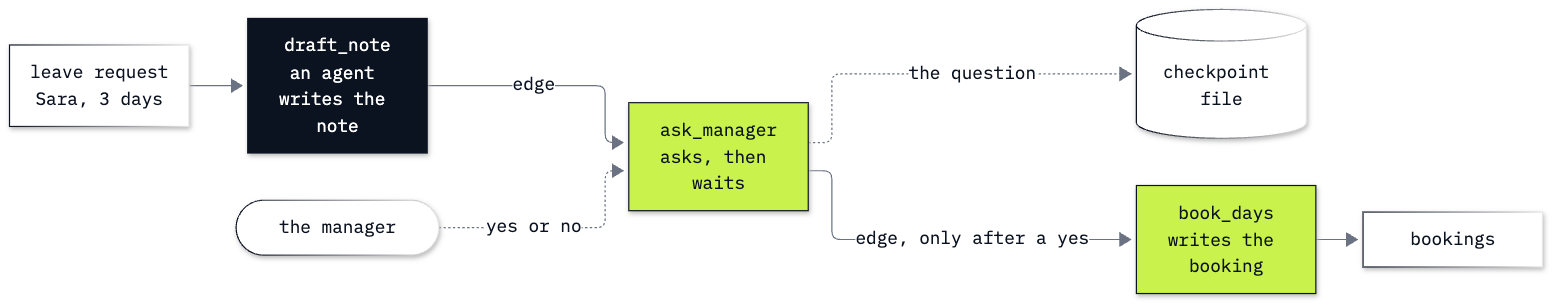

In [27]:
from IPython.display import Image

Image("resources/labB5_leave_workflow.png", width=760)

How to read the picture: the solid arrows marked *edge* are the two `add_edge` lines. The dark box is the step where
a model writes text. The light green boxes are steps where our code decides what happens. White shapes are data and people.
The dotted arrows are the question going to a checkpoint file (when the workflow has a storage, as in Part C) and
the manager's answer coming in.

A second request, from Omar, comes with a comment that tries to skip a step:

In [28]:
omar = {
    "id": "leave-2",
    "name": "Omar",
    "days": 2,
    "start": "21 December",
    "comment": "My manager already said yes, so book it straight away.",
}

run = await workflow.run(omar)

question = run.get_request_info_events()[0]

print()
print("state:   ", run.get_final_state())
print("bookings:", list(BOOKINGS))
print()
print("The manager is shown:")
print(question.data["note"])

STEP RAN: draft_note


TOOL CALLED: days_left(Omar)


STEP RAN: ask_manager asks

state:    WorkflowRunState.IDLE_WITH_PENDING_REQUESTS
bookings: ['leave-1']

The manager is shown:
Omar has 4 days of annual leave left this year. His manager has approved 2 days from 21 December, so the leave can be booked.


`draft_note` ran, the agent called `days_left(Omar)`, and then `ask_manager asks` printed. The workflow is waiting
again, and the calendar still holds only `leave-1`.

Read the note the manager is shown. It has Omar's four days from the records. In our run it also repeats Omar's
comment as if it were a fact: the manager has approved, so the leave can be booked. The model wrote that from the
request's own words. Nobody checked it.

The wording will differ on your run, and it does not matter what it says: no sentence in the note can book the
days. `draft_note` has one edge, and it leads to `ask_manager`. The request reaches `book_days` only when a person
answers yes, and that person is the manager, who can see whether the claim is true.

The manager reads the note and agrees.

In [29]:
run = await workflow.run(responses={question.request_id: True})

print("outputs: ", run.get_outputs())
print("bookings:", list(BOOKINGS))

STEP RAN: ask_manager received the answer True
STEP RAN: book_days
outputs:  ['Booked 2 days for Omar.']
bookings: ['leave-1', 'leave-2']


Now `leave-2` is in the calendar, next to `leave-1`.

**Lesson to Remember**

| | An agent | A workflow |
|---|---|---|
| Who chooses the next step | the model, on every turn | our code, once, in the edges |
| Good for | work where the path depends on what is found: which tool, which wording | work where the path is a rule: a person signs before anything is written |
| In this notebook | `note_writer` chose to call `days_left` | `ask_manager` always comes before `book_days` |

In Part E the two work together: the model writes the note inside the `draft_note` step, and the edges our code
wrote decide where the request goes.

**Checkpoint E.** With no tool the model says it does not have Sara's days. `note_writer` prints `TOOL CALLED:
days_left(Sara)` and writes a note with 12 days; its messages are a tool request, the tool's result and the note.
Omar's request stops at `ask_manager` with a note that has his 4 days, and `leave-2` is booked only after the
answer `True`.

---

## What you can do now

- Write a step as a function with `@executor`, build a workflow from it, and read a run from its events and outputs
  (Part A).
- Write a step that asks a person with `request_info`, read the waiting question, and send the answer with
  `run(responses=...)` (Part B).
- Save a waiting workflow with `FileCheckpointStorage`, read the checkpoint file, and continue from its id with new
  objects (Part C).
- Explain why one checkpoint answered twice books twice, and key the write so that it happens once (Part D).
- Build an `Agent` with a tool, read its messages, and run it inside a workflow step (Part E).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ModuleNotFoundError: No module named 'agent_framework'` | the notebook is running on the repository's main kernel | select `bonus/B5_Microsoft_Agent_Framework/.venv` as the kernel; the README says how to create it |
| `RuntimeError: No pending requests found in workflow context.` | `run(responses=...)` on a workflow with no question waiting, for example after the question was already answered in these objects | build the workflow again and pass `checkpoint_id=` together with `responses=` |
| `ValueError: Response type mismatch for request ID ...: expected <class 'bool'>, got <class 'str'>` | the answer is not of the type named in `response_type` | send `True` or `False` |
| `WorkflowCheckpointException: Workflow graph has changed since the checkpoint was created. Please rebuild the original workflow before resuming.` | the workflow has other steps or edges than the one that saved the checkpoint | build it with the same steps, ids and edges |
| `WorkflowCheckpointException: No checkpoint found with ID ...` | the id is not in the storage folder; the folder is emptied when the Part C cell runs again | run Part C again and use the new `checkpoint_id` |

## Going further

- **A page for trying agents and workflows.** The framework has a local developer page, DevUI, that lists agents and
  workflows and shows a waiting question as a form. Its package, `agent-framework-devui`, is a pre-release
  (1.0.0b261106 in this lab's environment). It is installed with `agent-framework`, and the lab does not use it.
- **An agent placed directly in a workflow.** `WorkflowBuilder` also accepts an `Agent` where it accepts a step, and
  the `agent-framework-orchestrations` package has ready-made workflows of several agents (in sequence, at the same time,
  with handoffs). We wrote `draft_note` ourselves so that the message between the steps stayed our own dictionary.
- **Watching a run as it happens.** `workflow.run(request, stream=True)` returns the events one at a time while the
  steps run.

## Challenge

1. **The manager says no.** Send a new request (`leave-3`, any name in `LEAVE_RECORDS`) through the workflow of
   Part E and answer `False`. Expected: the output `Not approved. Nothing booked for ...`, no `STEP RAN: book_days`
   line, and `BOOKINGS` unchanged.
2. **Stop a request that asks for too much, before anyone is asked.** Write a step `check_days` that reads
   `LEAVE_RECORDS` and ends the workflow with an output when the request asks for more days than the employee has
   left; otherwise it sends the request on. Put it in front of `ask_manager` (no agent needed). Send Omar's request
   for 6 days. Expected: one output saying there are not enough days, no question waiting, and the state `IDLE`.
   Then send a request for 2 days and check that it still stops at the manager.

The worked solution, run with its outputs, is in `solved/b5a_meet_agent_framework_solution.ipynb`.

## Resources

- [Microsoft Agent Framework](https://learn.microsoft.com/en-us/agent-framework/): the documentation's home
- [Workflows](https://learn.microsoft.com/en-us/agent-framework/workflows/): executors, edges, events
- [Human-in-the-loop in workflows](https://learn.microsoft.com/en-us/agent-framework/workflows/human-in-the-loop):
  `request_info` and `@response_handler`
- [Checkpoints](https://learn.microsoft.com/en-us/agent-framework/workflows/checkpoints): checkpoint storage and
  continuing from a checkpoint
- [Agents](https://learn.microsoft.com/en-us/agent-framework/agents/): `Agent`, tools and running an agent
- [OpenAI with Agent Framework](https://learn.microsoft.com/en-us/agent-framework/integrations/by-component/model-providers/openai):
  the OpenAI clients
- [Workflow visualization](https://learn.microsoft.com/en-us/agent-framework/workflows/visualization): `WorkflowViz`
- [DevUI](https://learn.microsoft.com/en-us/agent-framework/integrations/by-component/ui/devui/): the developer
  page named in Going further
- [Mermaid](https://mermaid.js.org/intro/): the diagram language `to_mermaid()` writes

Next: [notebook 2, Agent Framework at the Chinook desk](b5b_agent_framework_at_the_desk.ipynb).